In [12]:
import pandas as pd
d = pd.read_csv("bdd100k_merged.csv")
d.head()

,split,image,category,traffic_light_color,occluded,truncated,x1,y1,x2,y2
0,train,bdd100k_images_100k/100k/train/0000f77c-6257be...,traffic light,green,False,False,1125.902264,133.184488,1156.978645,210.875445
1,train,bdd100k_images_100k/100k/train/0000f77c-6257be...,traffic light,green,False,False,1156.978645,136.637417,1191.507960,210.875443
2,train,bdd100k_images_100k/100k/train/0000f77c-6257be...,traffic sign,none,False,False,1101.731743,211.122087,1170.790370,233.566141
3,train,bdd100k_images_100k/100k/train/0000f77c-6257be...,traffic sign,none,False,True,0.000000,0.246631,100.381647,122.825696
4,train,bdd100k_images_100k/100k/train/0000f77c-6257be...,car,none,False,False,45.240919,254.530367,357.805838,487.906215


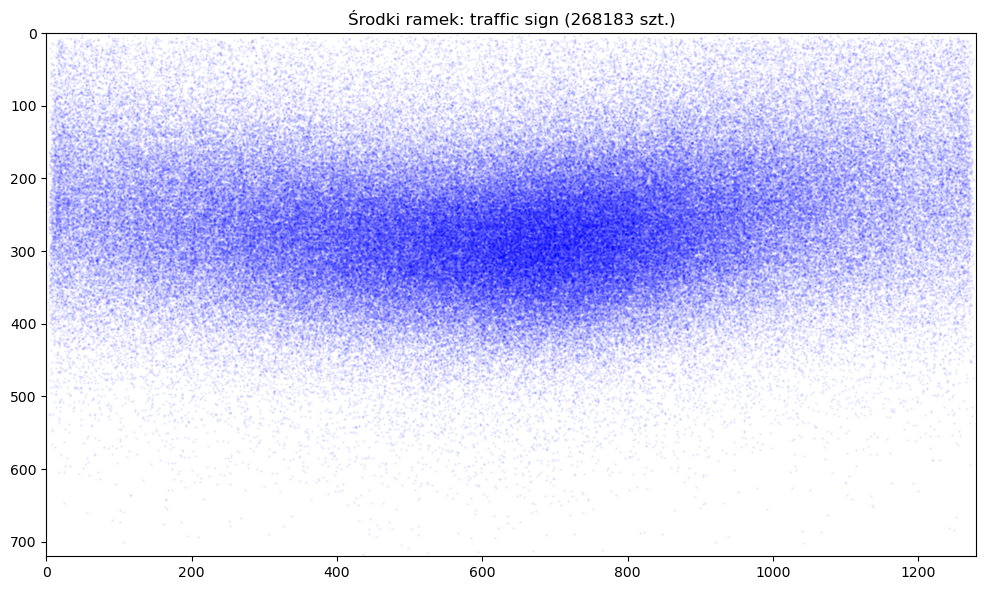

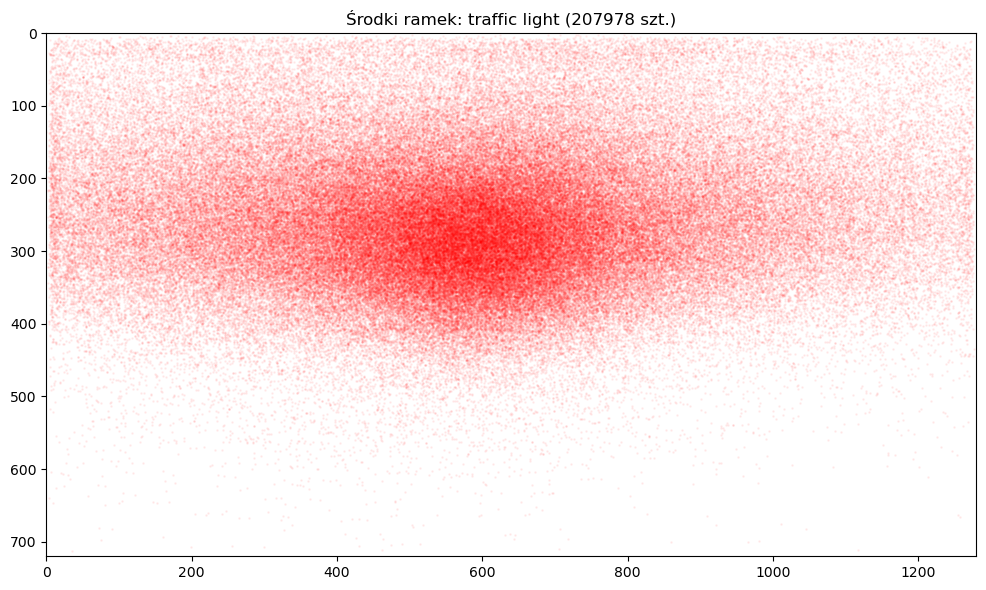

In [13]:
import matplotlib.pyplot as plt

# Rysuje środek każdej ramki danej kategorii na białym tle o rozmiarze zdjęcia (1280 x 720)
def pokaz_srodki(kategoria, kolor):
    ramki = d[d["category"] == kategoria]
    cx = (ramki["x1"] + ramki["x2"]) / 2   # środek w poziomie
    cy = (ramki["y1"] + ramki["y2"]) / 2   # środek w pionie

    plt.figure(figsize=(12, 7))
    plt.scatter(cx, cy, s=1, alpha=0.05, color=kolor)  # alpha -> im ciemniej, tym gęściej
    plt.xlim(0, 1280)
    plt.ylim(720, 0)                      # oś Y w dół, tak jak na zdjęciu
    plt.gca().set_aspect("equal")
    plt.title(f"Środki ramek: {kategoria} ({len(ramki)} szt.)")
    plt.show()

pokaz_srodki("traffic sign", "blue")
pokaz_srodki("traffic light", "red")

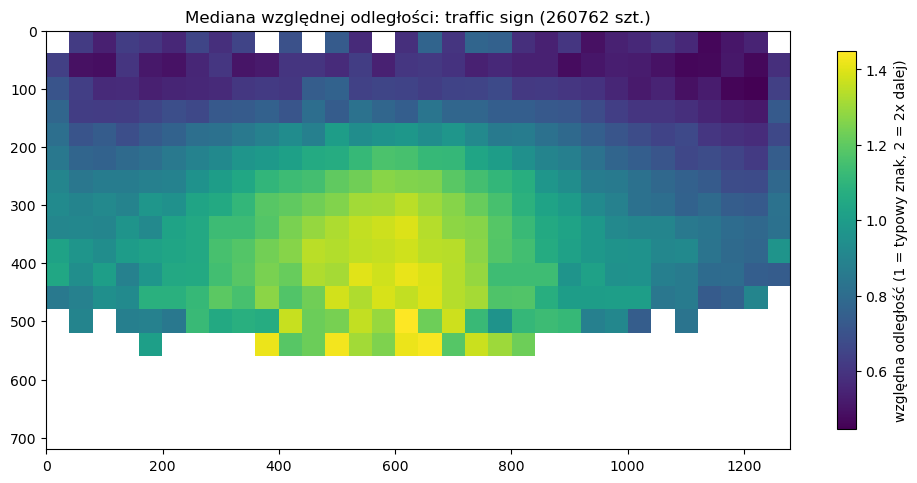

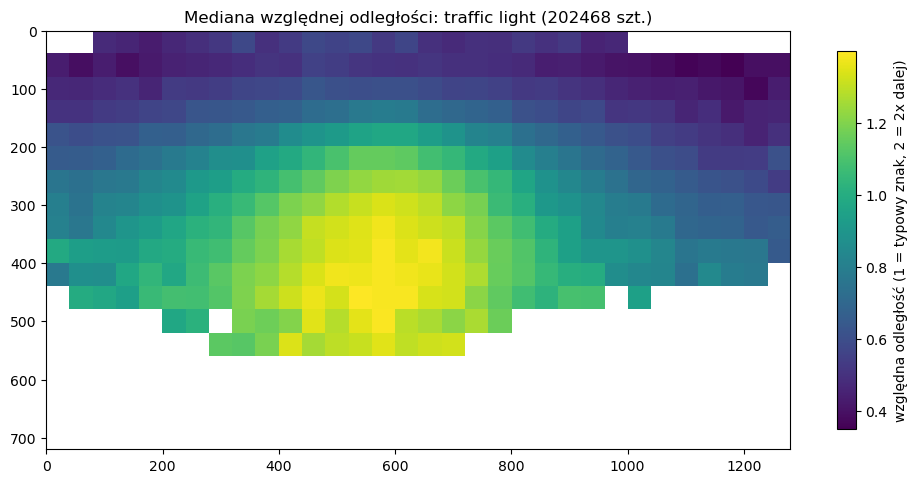

In [14]:
import numpy as np

# Nie znamy prawdziwej odległości, ale znaki mają podobny rozmiar w rzeczywistości,
# więc im mniejsza ramka na zdjęciu, tym znak jest dalej (odległość ~ 1 / rozmiar ramki).
# Względna odległość = mediana rozmiaru wszystkich znaków / rozmiar tego znaku
#   1 = typowy znak, 2 = dwa razy dalej niż typowy, 0.5 = dwa razy bliżej.

KRATKA = 40       # obraz dzielimy na kratki 40 x 40 px
MIN_ZNAKOW = 30   # kratki z mniejszą liczbą znaków pomijamy (za mało danych)

def mapa_odleglosci(kategoria):
    # pomijamy ramki ucięte przez krawędź zdjęcia - są sztucznie małe
    ramki = d[(d["category"] == kategoria) & (d["truncated"] == False)].copy()

    bok = np.sqrt((ramki["x2"] - ramki["x1"]) * (ramki["y2"] - ramki["y1"]))  # "średni bok" ramki
    ramki["odl"] = bok.median() / bok
    ramki["kol"] = ((ramki["x1"] + ramki["x2"]) / 2 // KRATKA).astype(int)     # numer kratki w poziomie
    ramki["wiersz"] = ((ramki["y1"] + ramki["y2"]) / 2 // KRATKA).astype(int)  # numer kratki w pionie

    # w każdej kratce liczymy medianę odległości znaków, których środek do niej wpada
    mapa = np.full((720 // KRATKA, 1280 // KRATKA), np.nan)
    for w in range(mapa.shape[0]):
        for k in range(mapa.shape[1]):
            w_kratce = ramki[(ramki["wiersz"] == w) & (ramki["kol"] == k)]
            if len(w_kratce) >= MIN_ZNAKOW:
                mapa[w, k] = w_kratce["odl"].median()

    plt.figure(figsize=(12, 7))
    plt.imshow(mapa, extent=[0, 1280, 720, 0], cmap="viridis")
    plt.colorbar(label="względna odległość (1 = typowy znak, 2 = 2x dalej)", shrink=0.7)
    plt.title(f"Mediana względnej odległości: {kategoria} ({len(ramki)} szt.)")
    plt.show()

mapa_odleglosci("traffic sign")
mapa_odleglosci("traffic light")

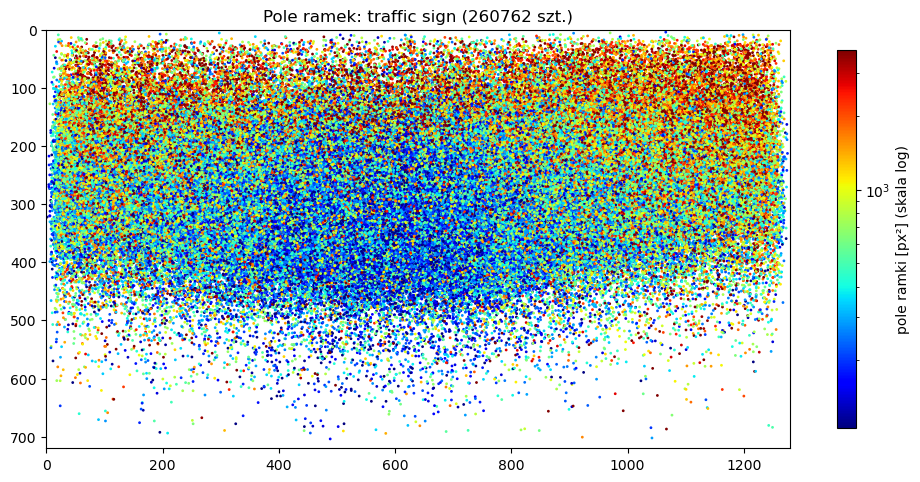

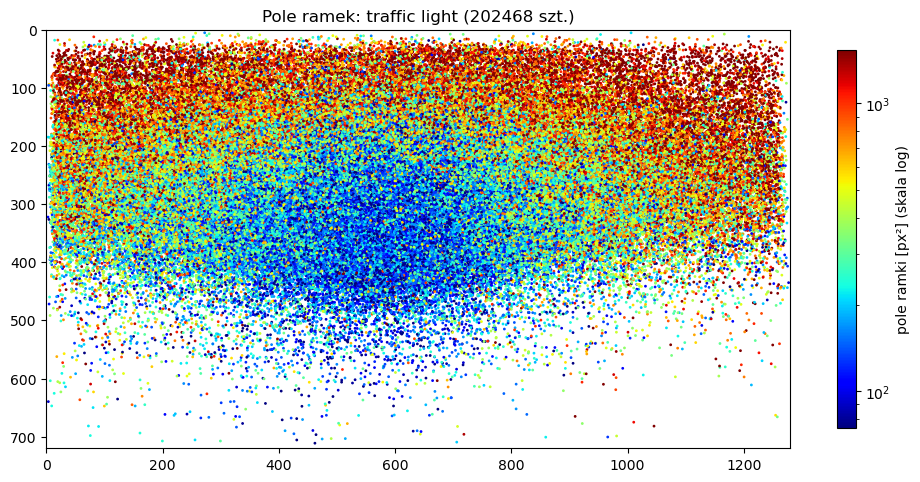

In [15]:
# Każdy znak = kropka w miejscu środka ramki, kolor kropki = pole ramki (szerokość * wysokość)
def pokaz_pola(kategoria):
    # pomijamy ramki ucięte przez krawędź zdjęcia - ich pole jest zaniżone
    ramki = d[(d["category"] == kategoria) & (d["truncated"] == False)]
    cx = (ramki["x1"] + ramki["x2"]) / 2
    cy = (ramki["y1"] + ramki["y2"]) / 2
    pole = (ramki["x2"] - ramki["x1"]) * (ramki["y2"] - ramki["y1"])

    plt.figure(figsize=(12, 7))
    # skala log, bo pola mają bardzo różne rzędy wielkości;
    # zakres kolorów 5%-95%, żeby kilka skrajnych ramek nie "spłaszczyło" kolorów
    plt.scatter(cx, cy, c=pole, s=1, cmap="jet", norm="log",
                vmin=pole.quantile(0.05), vmax=pole.quantile(0.95))
    plt.colorbar(label="pole ramki [px²] (skala log)", shrink=0.7)
    plt.xlim(0, 1280)
    plt.ylim(720, 0)   # oś Y w dół, tak jak na zdjęciu
    plt.gca().set_aspect("equal")
    plt.title(f"Pole ramek: {kategoria} ({len(ramki)} szt.)")
    plt.show()

pokaz_pola("traffic sign")
pokaz_pola("traffic light")

## Detektor znaków drogowych (metody klasyczne)

1. **Kandydaci** – miejsca, które *mogą* być znakiem:
   - maski kolorów w HSV (czerwony, żółty, zielony, niebieski, biały) + kontury,
   - MSER – jednolite plamy jasności (łapie też znaki ciemne / nocą),
   - tylko górna część obrazu (y < 500) i typowe rozmiary/proporcje – wynik analizy rozkładu znaków.
2. **Cechy kandydata:**
   - HOG (kształt krawędzi) i histogram kolorów HSV,
   - położenie i rozmiar względem **typowego rozmiaru znaku w danym miejscu obrazu** (mapa z analizy powyżej) – we wcześniejszym teście podniosły F1 z 0.14 do 0.16 (sam HOG: 0.09),
   - **rozpoznany kolor i kształt konturu** (udział koloru, liczba wierzchołków, okrągłość, wypełnienie).
3. **Klasyfikator „znak / nie znak”** – porównujemy regresję logistyczną, SVM, las losowy i gradient boosting; zostaje najlepszy na obrazach do strojenia.

Na końcu usuwamy zduplikowane ramki (NMS) i liczymy precision / recall / F1 / accuracy przy IoU ≥ 0.5.

**Accuracy w detekcji:** zwykłe (TP + TN) / wszystko nie ma sensu, bo TN (poprawnie niewykryte tło) jest nieskończenie wiele. Dlatego liczymy accuracy = TP / (TP + FP + FN).

In [16]:
import cv2
import random
from skimage.feature import hog
from sklearn.ensemble import HistGradientBoostingClassifier

YMAX = 500   # z mapy środków ramek: poniżej y = 500 prawie nie ma znaków

mser = cv2.MSER_create()   # MSER = wykrywanie jednolitych plam jasności (klasyczna metoda)
mser.setMinArea(30)
mser.setMaxArea(5000)

def maski_kolorow(hsv):
    # maski typowych kolorów znaków (progi dobrane na wycinkach znaków z train)
    H, S, V = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
    kolorowe = (S > 60) & (V > 40)
    return {
        "czerwony": kolorowe & ((H < 10) | (H > 165)),
        "żółty": kolorowe & (H >= 10) & (H < 35),
        "zielony": kolorowe & (H >= 70) & (H < 100),    # tablice z nazwami ulic
        "niebieski": kolorowe & (H >= 100) & (H < 130),
        "biały": (S < 50) & (V > 150),
    }

def iou(a, b):
    # a, b = (x1, y1, x2, y2); IoU = pole części wspólnej / pole sumy
    wspolne = max(0, min(a[2], b[2]) - max(a[0], b[0])) * max(0, min(a[3], b[3]) - max(a[1], b[1]))
    suma = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - wspolne
    return wspolne / suma if suma > 0 else 0

znaki = d[d["category"] == "traffic sign"]   # wszystkie ramki znaków

def ramki_gt(sciezka):
    # prawdziwe ramki znaków na danym obrazie
    z = znaki[znaki["image"] == sciezka]
    return [(r.x1, r.y1, r.x2, r.y2) for r in z.itertuples()]

def ramki_z_maski(maska):
    maska = maska.astype(np.uint8) * 255
    maska = cv2.morphologyEx(maska, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))  # zalep drobne dziury
    kontury, _ = cv2.findContours(maska, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return [cv2.boundingRect(k) for k in kontury]   # (x, y, szerokość, wysokość)

def kandydaci(img):
    gora = img[:YMAX]   # szukamy tylko w górnej części obrazu
    ramki = []
    for maska in maski_kolorow(cv2.cvtColor(gora, cv2.COLOR_BGR2HSV)).values():
        ramki += ramki_z_maski(maska)
    _, ramki_mser = mser.detectRegions(cv2.cvtColor(gora, cv2.COLOR_BGR2GRAY))
    ramki += [tuple(r) for r in ramki_mser]

    wynik = set()   # set usuwa powtórzone ramki
    for x, y, w, h in ramki:
        if 80 <= w * h <= 6000 and 0.3 <= w / h <= 4.5:   # typowe rozmiary i proporcje znaków
            wynik.add((x, y, x + w, y + h))
    return list(wynik)

### Rozpoznawanie koloru i kształtu (klasycznie)

- **Kolor** – który z kolorów znaków (te same maski HSV co przy kandydatach) zajmuje największą część wycinka; poniżej 15% → „ciemny/inny”.
- **Kształt** – największy kontur w masce tego koloru → otoczka wypukła (zamyka dziury po napisach) → uproszczenie do wielokąta (`approxPolyDP`):
  wypełnienie ramki > 0.88 → prostokąt, 3 wierzchołki → trójkąt, 4 → romb, okrągłość > 0.8 → koło, reszta → inny.

In [17]:
def kolor_i_ksztalt(wycinek):
    # 1) KOLOR: którego koloru znaków jest najwięcej w wycinku
    maski = maski_kolorow(cv2.cvtColor(wycinek, cv2.COLOR_BGR2HSV))
    kolor = max(maski, key=lambda k: maski[k].mean())
    udzial = maski[kolor].mean()
    if udzial < 0.15:
        return "ciemny/inny", "nieznany", [udzial, 0, 0, 0]

    # 2) KSZTAŁT: największy kontur w masce tego koloru -> otoczka wypukła (znaki są wypukłe,
    #    a otoczka "zamyka" dziury po napisach) -> uproszczenie do wielokąta
    maska = cv2.morphologyEx(maski[kolor].astype(np.uint8) * 255, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    kontury, _ = cv2.findContours(maska, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    kontur = cv2.convexHull(max(kontury, key=cv2.contourArea))
    pole = cv2.contourArea(kontur)
    obwod = max(1, cv2.arcLength(kontur, True))
    wierzcholki = len(cv2.approxPolyDP(kontur, 0.04 * obwod, True))
    okraglosc = 4 * np.pi * pole / obwod ** 2          # 1 = idealne koło
    x, y, w, h = cv2.boundingRect(kontur)
    wypelnienie = pole / max(1, w * h)                 # ile ramki zajmuje figura: prostokąt ~1, koło ~0.79, romb/trójkąt ~0.5

    if wypelnienie > 0.88:
        ksztalt = "prostokąt"
    elif wierzcholki == 3:
        ksztalt = "trójkąt"
    elif wierzcholki == 4:
        ksztalt = "romb"
    elif okraglosc > 0.8:
        ksztalt = "koło"
    else:
        ksztalt = "inny"
    return kolor, ksztalt, [udzial, wierzcholki, okraglosc, wypelnienie]

def rozpoznaj(img, r):
    x1, y1, x2, y2 = [int(v) for v in r]
    if x2 - x1 < 2 or y2 - y1 < 2:
        return "za mały", "nieznany", [0, 0, 0, 0]
    return kolor_i_ksztalt(cv2.resize(img[y1:y2, x1:x2], (64, 64)))

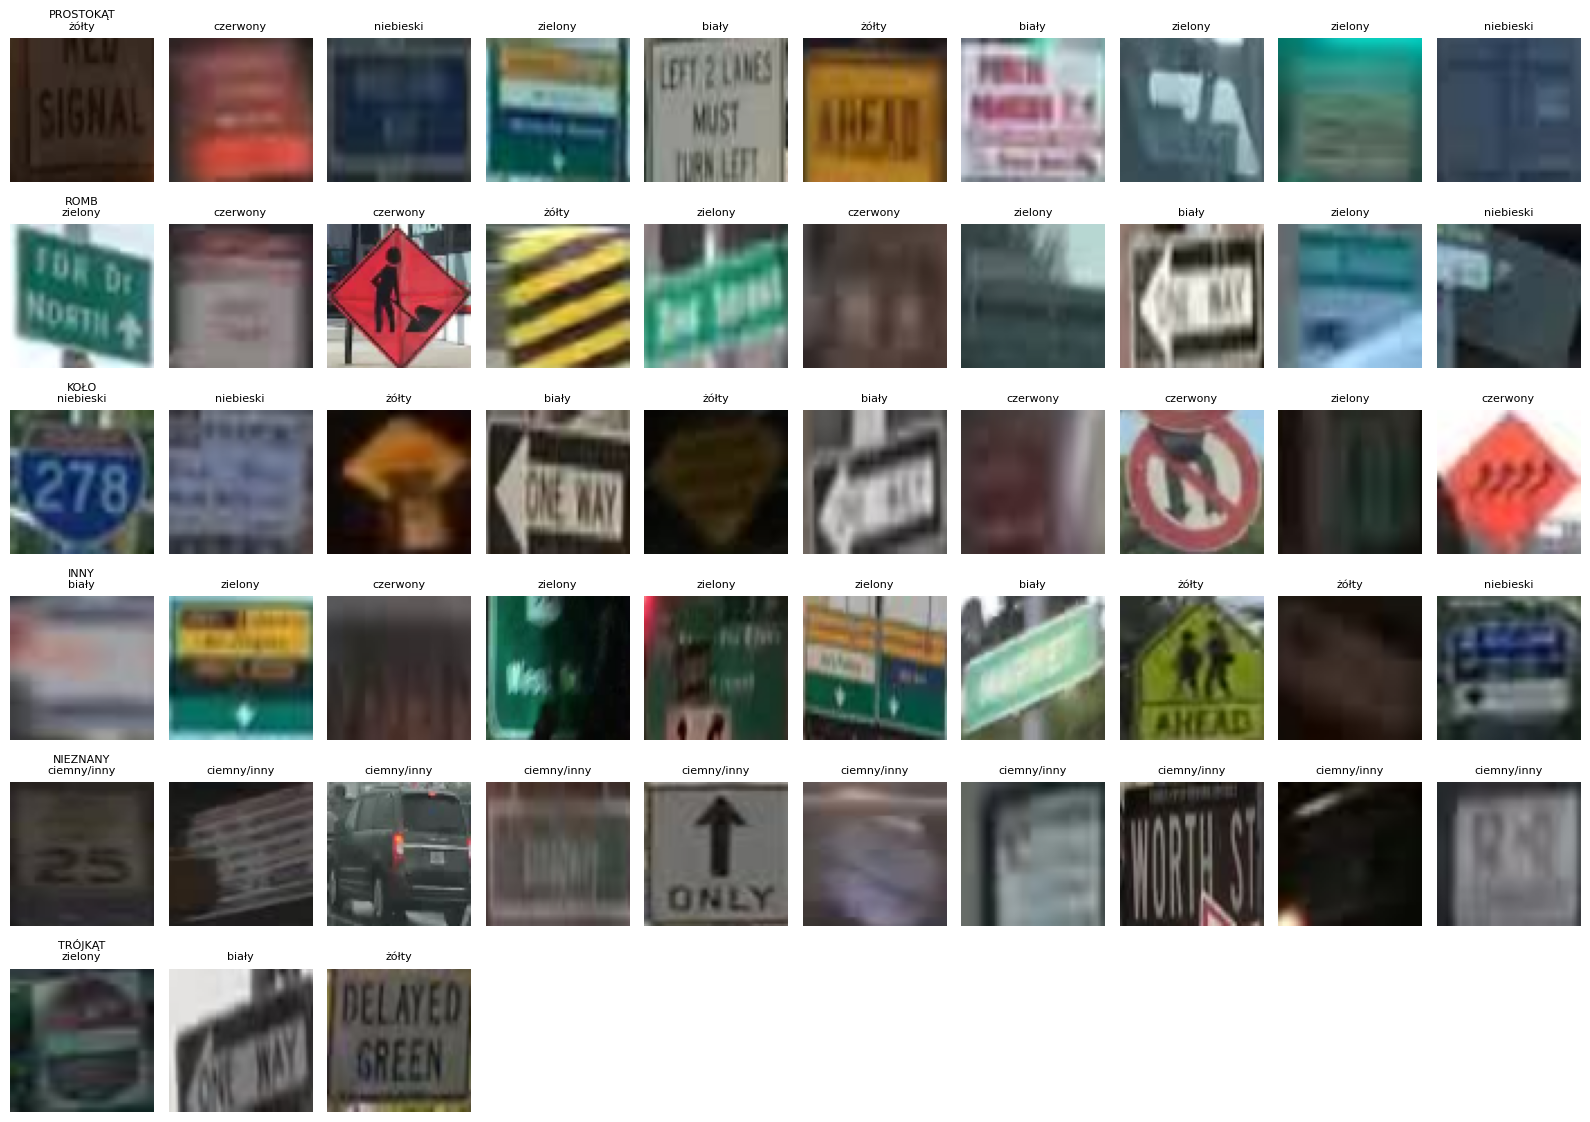

{'prostokąt': 143, 'romb': 78, 'koło': 65, 'inny': 11, 'nieznany': 100, 'trójkąt': 3}


In [18]:
# Sprawdzenie rozpoznawania na prawdziwych znakach z train: po 10 przykładów każdego kształtu
przyklady = znaki[(znaki["split"] == "train") & ((znaki["x2"] - znaki["x1"]) * (znaki["y2"] - znaki["y1"]) > 600)]
przyklady = przyklady.sample(400, random_state=0)

grupy = {}
for r in przyklady.itertuples():
    img = cv2.imread(r.image)
    kolor, ksztalt, _ = rozpoznaj(img, (r.x1, r.y1, r.x2, r.y2))
    wycinek = cv2.resize(img[int(r.y1):int(r.y2), int(r.x1):int(r.x2)], (64, 64))
    grupy.setdefault(ksztalt, []).append((wycinek, kolor))

plt.figure(figsize=(16, 1.9 * len(grupy)))
for w, ksztalt in enumerate(grupy):
    for k, (wycinek, kolor) in enumerate(grupy[ksztalt][:10]):
        plt.subplot(len(grupy), 10, w * 10 + k + 1)
        plt.imshow(cv2.cvtColor(wycinek, cv2.COLOR_BGR2RGB))
        plt.title(f"{ksztalt.upper()}\n{kolor}" if k == 0 else kolor, fontsize=8)
        plt.axis("off")
plt.tight_layout()
plt.show()
print({ksztalt: len(grupy[ksztalt]) for ksztalt in grupy})

In [19]:
KRATKA = 40

# Oczekiwane pole znaku w każdej kratce 40x40 px (mediana z danych treningowych)
tren = d[(d["split"] == "train") & (d["category"] == "traffic sign") & (d["truncated"] == False)].copy()
tren["pole"] = (tren["x2"] - tren["x1"]) * (tren["y2"] - tren["y1"])
tren["kol"] = ((tren["x1"] + tren["x2"]) / 2 // KRATKA).astype(int)
tren["wiersz"] = ((tren["y1"] + tren["y2"]) / 2 // KRATKA).astype(int)

mapa_pola = np.full((720 // KRATKA, 1280 // KRATKA), tren["pole"].median())   # domyślnie: mediana całości
for w in range(mapa_pola.shape[0]):
    for k in range(mapa_pola.shape[1]):
        w_kratce = tren[(tren["wiersz"] == w) & (tren["kol"] == k)]
        if len(w_kratce) >= 30:
            mapa_pola[w, k] = w_kratce["pole"].median()

def cechy(img, r):
    x1, y1, x2, y2 = [int(v) for v in r]
    wycinek = cv2.resize(img[y1:y2, x1:x2], (32, 32))

    # 1) kształt: HOG (histogram kierunków krawędzi)
    szary = cv2.cvtColor(wycinek, cv2.COLOR_BGR2GRAY)
    f_hog = hog(szary, pixels_per_cell=(8, 8), cells_per_block=(2, 2))

    # 2) kolor: histogram odcienia (H) i nasycenia (S)
    hsv = cv2.cvtColor(wycinek, cv2.COLOR_BGR2HSV)
    f_kolor = cv2.calcHist([hsv], [0, 1], None, [8, 4], [0, 180, 0, 256]).flatten() / (32 * 32)

    # 3) położenie i rozmiar: czy ramka ma rozmiar typowy dla znaku w tym miejscu obrazu?
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    oczekiwane_pole = mapa_pola[int(cy // KRATKA), int(cx // KRATKA)]
    pole = (x2 - x1) * (y2 - y1)
    f_polozenie = [cy / 720, abs(cx - 640) / 640, np.log(pole / oczekiwane_pole), (x2 - x1) / (y2 - y1)]

    # 4) kolor i kształt konturu: udział koloru, liczba wierzchołków, okrągłość, wypełnienie
    _, _, f_kontur = rozpoznaj(img, r)

    return np.concatenate([f_hog, f_kolor, f_polozenie, f_kontur])

In [20]:
# Zbiór uczący dla klasyfikatora (ok. 5 min)
obrazy_train = pd.Series(d[d["split"] == "train"]["image"].unique()).sample(2200, random_state=1).tolist()
obrazy_uczace = obrazy_train[:2000]     # do uczenia klasyfikatora
obrazy_strojenie = obrazy_train[2000:]  # do wyboru klasyfikatora i progu
obrazy_test = pd.Series(d[d["split"] == "val"]["image"].unique()).sample(500, random_state=1).tolist()

random.seed(0)
X, y = [], []
for sciezka in obrazy_uczace:
    img = cv2.imread(sciezka)
    gt = ramki_gt(sciezka)

    # pozytywne: prawdziwe ramki znaków
    for r in gt:
        if (r[2] - r[0]) * (r[3] - r[1]) >= 80 and r[2] - r[0] > 2 and r[3] - r[1] > 2:
            X.append(cechy(img, r)); y.append(1)

    # kandydaci: trafiający w znak -> pozytywni, chybieni -> negatywni (max 30 losowych na obraz)
    negatywne = []
    for r in kandydaci(img):
        najlepsze_iou = max([iou(r, g) for g in gt], default=0)
        if najlepsze_iou >= 0.5:
            X.append(cechy(img, r)); y.append(1)
        elif najlepsze_iou < 0.3:
            negatywne.append(r)
    random.shuffle(negatywne)
    for r in negatywne[:30]:
        X.append(cechy(img, r)); y.append(0)

X = np.array(X, dtype=np.float32)
y = np.array(y)
print("przykładów:", len(y), "w tym znaków:", y.sum())

przykładów: 70015 w tym znaków: 10126


In [21]:
# Dla obrazów do strojenia i testu liczymy kandydatów i ich cechy tylko raz,
# potem szybko sprawdzamy różne klasyfikatory i progi (ok. 5 min)
def przygotuj(obrazy):
    dane = []
    for sciezka in obrazy:
        img = cv2.imread(sciezka)
        kand = kandydaci(img)
        F = np.array([cechy(img, r) for r in kand], dtype=np.float32)
        dane.append({"obraz": sciezka, "gt": ramki_gt(sciezka), "kand": kand, "cechy": F})
    return dane

dane_strojenie = przygotuj(obrazy_strojenie)
dane_test = przygotuj(obrazy_test)

KeyboardInterrupt: 

In [ ]:
def nms(ramki, wyniki):
    # Usuwanie duplikatów: idziemy od najpewniejszej ramki i odrzucamy te, które na nią zachodzą
    kolejnosc = np.argsort(wyniki)[::-1]
    przyjete = []
    for i in kolejnosc:
        a = ramki[i]
        dobra = True
        for b in przyjete:
            wspolne = max(0, min(a[2], b[2]) - max(a[0], b[0])) * max(0, min(a[3], b[3]) - max(a[1], b[1]))
            mniejsza = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
            if iou(a, b) >= 0.3 or wspolne / mniejsza > 0.6:   # mocno zachodzą albo jedna leży w drugiej
                dobra = False
        if dobra:
            przyjete.append(a)
    return przyjete

def wykryj(kand, p, prog):
    # zostawiamy kandydatów z prawdopodobieństwem "to znak" > prog i usuwamy duplikaty
    ramki = [kand[i] for i in range(len(kand)) if p[i] > prog]
    wyniki = [p[i] for i in range(len(kand)) if p[i] > prog]
    return nms(ramki, wyniki)

def wykryj_znaki(img, model, prog):
    # cały detektor dla jednego obrazu
    kand = kandydaci(img)
    if len(kand) == 0:
        return []
    p = model.predict_proba(np.array([cechy(img, r) for r in kand]))[:, 1]
    return wykryj(kand, p, prog)

def policz_p(dane, model, kolumny=slice(None)):
    # prawdopodobieństwo "to znak" dla każdego kandydata (liczone raz dla danego modelu)
    for o in dane:
        o["p"] = model.predict_proba(o["cechy"][:, kolumny])[:, 1] if len(o["kand"]) > 0 else []

def dopasuj(gt, wykryte):
    # trafione[i]   - czy i-ta wykryta ramka trafiła w znak (IoU >= 0.5)
    # znalezione[j] - czy j-ty prawdziwy znak został wykryty
    znalezione = [False] * len(gt)
    trafione = []
    for r in wykryte:
        ious = [iou(r, g) if not znalezione[j] else 0 for j, g in enumerate(gt)]
        if len(gt) > 0 and max(ious) >= 0.5:
            znalezione[int(np.argmax(ious))] = True
            trafione.append(True)
        else:
            trafione.append(False)
    return trafione, znalezione

def ocen(dane, prog):
    TP = FP = FN = 0
    for o in dane:
        trafione, znalezione = dopasuj(o["gt"], wykryj(o["kand"], o["p"], prog))
        TP += trafione.count(True)
        FP += trafione.count(False)
        FN += znalezione.count(False)
    P = TP / max(1, TP + FP)
    R = TP / max(1, TP + FN)
    F1 = 2 * P * R / max(1e-9, P + R)
    # W detekcji nie ma TN (każdy kawałek tła byłby "poprawnie niewykrytym" obiektem),
    # więc accuracy = trafione / (trafione + fałszywe wykrycia + przeoczone)
    A = TP / max(1, TP + FP + FN)
    return P, R, F1, A

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# Porównanie klasyfikatorów na tych samych cechach (ok. 3 min)
modele = {
    "regresja logistyczna": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(probability=True, random_state=0)),
    "las losowy": RandomForestClassifier(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=0),
    "gradient boosting": HistGradientBoostingClassifier(max_iter=300, random_state=0),
}
losowe = np.random.default_rng(0).choice(len(y), 10000, replace=False)   # SVM jest wolny - uczymy go na 10 000 przykładów
progi = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

wyniki = []
for nazwa, m in modele.items():
    if nazwa == "SVM (RBF)":
        m.fit(X[losowe], y[losowe])
    else:
        m.fit(X, y)
    policz_p(dane_strojenie, m)
    for prog in progi:
        P, R, F1, A = ocen(dane_strojenie, prog)
        wyniki.append({"model": nazwa, "prog": prog, "precision": P, "recall": R, "F1": F1, "accuracy": A})

wyniki = pd.DataFrame(wyniki)
najlepsze = wyniki.loc[wyniki.groupby("model")["F1"].idxmax()]   # najlepszy próg dla każdego modelu
print(najlepsze.sort_values("F1", ascending=False).round(3).to_string(index=False))

najlepszy = najlepsze.loc[najlepsze["F1"].idxmax()]
model = modele[najlepszy["model"]]
PROG = najlepszy["prog"]
print("\nwybrany:", najlepszy["model"], " próg:", PROG)

In [ ]:
# Czy nowe cechy koloru i kształtu konturu (ostatnie 4 kolumny) coś dają? Ten sam model bez nich:
model_bez = HistGradientBoostingClassifier(max_iter=300, random_state=0).fit(X[:, :-4], y)
policz_p(dane_strojenie, model_bez, kolumny=slice(0, -4))
print("F1 bez cech kształtu konturu:", round(max(ocen(dane_strojenie, prog)[2] for prog in progi), 3))
print("F1 z cechami kształtu konturu:", round(najlepszy["F1"], 3))

In [ ]:
# Przykładowe wyniki na obrazach z val (podpis = rozpoznany kolor i kształt)
obrazy_ze_znakami = pd.Series(znaki[znaki["split"] == "val"]["image"].unique()).sample(4, random_state=3).tolist()

plt.figure(figsize=(16, 9))
for i, sciezka in enumerate(obrazy_ze_znakami):
    img = cv2.imread(sciezka)
    wykryte = wykryj_znaki(img, model, PROG)
    podpisy = [rozpoznaj(img, r) for r in wykryte]   # przed rysowaniem ramek (żeby nie zmieniać kolorów)
    for r in ramki_gt(sciezka):
        cv2.rectangle(img, (int(r[0]), int(r[1])), (int(r[2]), int(r[3])), (0, 255, 0), 2)   # zielone = prawda
    for r in wykryte:
        cv2.rectangle(img, (int(r[0]), int(r[1])), (int(r[2]), int(r[3])), (0, 0, 255), 2)   # czerwone = wykryte
    plt.subplot(2, 2, i + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    for r, (kolor, ksztalt, _) in zip(wykryte, podpisy):
        plt.text(r[0], r[1] - 5, f"{kolor}, {ksztalt}", color="red", fontsize=8)
    plt.axis("off")
plt.suptitle("Zielone = ramki referencyjne, czerwone = wykryte")
plt.tight_layout()
plt.show()

In [ ]:
# Test na obrazach z val (zbiór niewidziany przy uczeniu i wyborze klasyfikatora/progu)
policz_p(dane_test, model)
P, R, F1, A = ocen(dane_test, PROG)
print(f"TEST ({len(dane_test)} obrazów, {najlepszy['model']}, próg {PROG}):")
print(f"precision = {P:.3f}  recall = {R:.3f}  F1 = {F1:.3f}  accuracy = {A:.3f}")

## Analiza działania detektora (zbiór testowy)

Dla każdego prawdziwego znaku sprawdzamy, czy został wykryty (**recall**), a dla każdego wykrycia – czy trafiło w znak (**precision**).
Wyniki dzielimy według rozmiaru znaku oraz rozpoznanego koloru i kształtu.

In [ ]:
# Dla każdego znaku z testu: czy został wykryty? Dla każdego wykrycia: czy trafiło w znak?
wiersze_gt, wiersze_det = [], []
for o in dane_test:
    img = cv2.imread(o["obraz"])
    wykryte = wykryj(o["kand"], o["p"], PROG)
    trafione, znalezione = dopasuj(o["gt"], wykryte)
    for g, z in zip(o["gt"], znalezione):
        kolor, ksztalt, _ = rozpoznaj(img, g)
        pole = (g[2] - g[0]) * (g[3] - g[1])
        wiersze_gt.append({"obraz": o["obraz"], "ramka": g, "pole": pole, "kolor": kolor, "ksztalt": ksztalt, "wykryty": z})
    for r, t in zip(wykryte, trafione):
        kolor, ksztalt, _ = rozpoznaj(img, r)
        wiersze_det.append({"obraz": o["obraz"], "ramka": r, "kolor": kolor, "ksztalt": ksztalt, "trafiony": t})

gt_df = pd.DataFrame(wiersze_gt)
det_df = pd.DataFrame(wiersze_det)
gt_df["rozmiar"] = pd.cut(gt_df["pole"], [0, 200, 500, 1500, 6000, 1e7],
                          labels=["< 200 px²", "200-500", "500-1500", "1500-6000", "> 6000"])

print("RECALL - jaka część znaków została wykryta:\n")
for kol in ["rozmiar", "kolor", "ksztalt"]:
    print(gt_df.groupby(kol, observed=True)["wykryty"].agg(liczba="count", recall="mean").round(3), "\n")

print("PRECISION - jaka część wykryć to prawdziwe znaki:\n")
for kol in ["kolor", "ksztalt"]:
    print(det_df.groupby(kol, observed=True)["trafiony"].agg(liczba="count", precision="mean").round(3), "\n")

fig, osie = plt.subplots(1, 3, figsize=(16, 4))
for os_, kol in zip(osie, ["rozmiar", "kolor", "ksztalt"]):
    gt_df.groupby(kol, observed=True)["wykryty"].mean().plot.bar(ax=os_, color="steelblue", rot=30)
    os_.set_title(f"Recall wg: {kol}")
    os_.set_ylim(0, 1)
plt.tight_layout()
plt.show()

In [ ]:
def pokaz_przyklady(wiersze, tytul):
    plt.figure(figsize=(16, 3.5))
    for i, (_, w) in enumerate(wiersze.iterrows()):
        img = cv2.imread(w["obraz"])
        x1, y1, x2, y2 = [int(v) for v in w["ramka"]]
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 0, 255), 2)
        m = 60   # margines, żeby było widać otoczenie
        plt.subplot(1, len(wiersze), i + 1)
        plt.imshow(cv2.cvtColor(img[max(0, y1 - m):y2 + m, max(0, x1 - m):x2 + m], cv2.COLOR_BGR2RGB))
        plt.title(f"{w['kolor']}, {w['ksztalt']}", fontsize=9)
        plt.axis("off")
    plt.suptitle(tytul)
    plt.show()

pokaz_przyklady(det_df[~det_df["trafiony"]].sample(6, random_state=0), "False positives - wykrycia, które nie są znakami")
pokaz_przyklady(gt_df[~gt_df["wykryty"]].sample(6, random_state=0), "False negatives - przeoczone znaki")

## Wnioski

**Wynik na teście** (500 obrazów z val, IoU ≥ 0.5): precision ≈ 0.22, recall ≈ 0.14, F1 ≈ 0.17, accuracy ≈ 0.09.

**Porównanie klasyfikatorów** (obrazy do strojenia, F1 przy najlepszym progu): gradient boosting 0.171, SVM RBF 0.135 (uczony na 10 tys. przykładów, bo jest wolny), las losowy 0.134, regresja logistyczna 0.096.
Modele nieliniowe są wyraźnie lepsze od liniowego – granica „znak / nie znak” w przestrzeni cech jest złożona. Gradient boosting wygrał i jest szybki w predykcji.

**Kolor i kształt konturu jako cechy nie poprawiły F1** (0.171 z nimi i bez nich) – HOG opisuje już kształt krawędzi, a histogram HSV kolor. Rozpoznawanie koloru i kształtu przydaje się natomiast do opisu wykryć i analizy błędów. Samo rozpoznawanie kształtu jest zawodne dla małych, rozmytych i widzianych pod kątem znaków (prostokąt w perspektywie wygląda jak romb).

**Gdzie detektor działa, a gdzie nie:**
- **Rozmiar:** znaki < 200 px² są prawie niewykrywalne (recall ~5%), najlepiej wypadają 500–1500 px² (~20%). Ramki > 6000 px² odrzucamy już na etapie kandydatów (to ok. 3% znaków).
- **Kolor:** najlepiej zielone (~24%) i żółte (~22%) tablice – nasycone i jednolite; najgorzej ciemne/nocne (~3%) oraz białe i niebieskie (~8–9%), które mylą się z niebem i elewacjami.
- **Kształt:** najlepiej koła (~23%) i prostokąty (~17%). Trójkątów jest bardzo mało (w USA to rzadki kształt).
- **Precision** jest najwyższa dla zielonych wykryć (~34%) i kół (~35%), najniższa dla ciemnych (~8%).

**Typowe false positives:** czerwone światła sygnalizatorów (czerwone koło wygląda jak znak zakazu), okna budynków (białe prostokąty), prześwietlone liście i plamy światła w koronach drzew.

**Typowe false negatives:** znaki nocą (za ciemne, by przejść progi koloru), bardzo małe i odległe znaki, znaki częściowo zasłonięte (np. słupem) lub stojące tuż obok innego znaku tego samego koloru (maska koloru skleja je w jedną ramkę).

**Możliwe ulepszenia:**
- wyrównanie jasności (np. CLAHE) przed szukaniem kandydatów – pomoże nocą,
- douczanie na najczęstszych pomyłkach (hard negative mining: sygnalizatory, okna),
- odrzucanie wykryć pokrywających się z wykrytymi sygnalizatorami (po zrobieniu detektora świateł),
- okno przesuwne (sliding window) z HOG zamiast kandydatów z koloru/MSER – wyższy recall kosztem czasu.